
The goal of this project is to use the following data set of 15000 patients in India, "Diabetes Risk Prediction" (https://www.kaggle.com/datasets/mansiaggarwal88/diabetes-risk-prediction/data), to accurately assess diabetes risk by analyzing potential risk factors to create predictive models. These predictions could then hopefully be used to help patients identify and reduce potential diabetes risk in the future.

The dataset contains 19 different features for each of the 15000 included patients, and are listed below as follows with our target variable being diabetes_risk:

patient_id

age

gender

city

bmi

family_history_diabetes

physical_activity_level

diet_type

smoking_status

alcohol_consumption

hours_sleep_per_night

stress_level

fasting_blood_sugar

hba1c_level

blood_pressure_systolic

blood_pressure_diastolic

waist_circumference_cm

income_bracket

diabetes_risk

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.naive_bayes import MultinomialNB, CategoricalNB
from sklearn import metrics
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import RobustScaler, LabelEncoder, OrdinalEncoder
!pip install dython
from dython.nominal import associations

info_df = pd.read_csv("diabetes_risk.csv", encoding='latin1') 
target = ['diabetes_risk']

display(info_df.head(5))
print("Initial dataframe:", info_df.shape)
info_df.info()


,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


Initial dataframe: (15000, 19)
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  str    
 3   city                      15000 non-null  str    
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  str    
 6   physical_activity_level   15000 non-null  str    
 7   diet_type                 15000 non-null  str    
 8   smoking_status            14528 non-null  str    
 9   alcohol_consumption       11212 non-null  str    
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null 

Since patient_id, city, and income bracket are all demographic features with no significance to our analysis, we can drop those columns and then check for any empty values or missing data points. We can also encode relevant categorical data types later into integer values to make them easier to handle and examine.

In [2]:
info_df.drop(columns = ['patient_id','city', 'income_bracket'], inplace = True)
display(info_df.head(5))
info_df.isnull().sum()


,age,gender,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,diabetes_risk
0,47,Female,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,Low
1,53,Female,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low
2,47,Male,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,High
3,41,Male,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Low
4,57,Female,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,Low


age                            0
gender                         0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
diet_type                      0
smoking_status               472
alcohol_consumption         3788
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
diabetes_risk                  0
dtype: int64

There is unfortunately a signficant amount of missing data in regards to smoking and alcohol consumption, but we can either drop patients with incomplete data or add in unknowns and still have sufficient data points. Based on the amount and type of missing data, we chose to fill in null values with 'unknown' because removing them outright removes too large a portion of our data and the lack of response may be a useful insight for future exploration.

In [3]:
# filling null fields with 'unknown'
info_df['smoking_status'] = info_df['smoking_status'].fillna('Unknown')
info_df['alcohol_consumption'] = info_df['alcohol_consumption'].fillna('Unknown')

info_df.shape
info_df.isnull().sum() # double-checking to see if entries were corrected

age                         0
gender                      0
bmi                         0
family_history_diabetes     0
physical_activity_level     0
diet_type                   0
smoking_status              0
alcohol_consumption         0
hours_sleep_per_night       0
stress_level                0
fasting_blood_sugar         0
hba1c_level                 0
blood_pressure_systolic     0
blood_pressure_diastolic    0
waist_circumference_cm      0
diabetes_risk               0
dtype: int64

**Exploratory Data Analysis**

We can examine various plots to see if there is an immediately obvious feature affecting diabetes risk and to get a better idea of which other features are impacting our target variable. We'll first examine fasting blood sugar and HbA1c level, as both are closely associated with diabetes risk and glycemic status.

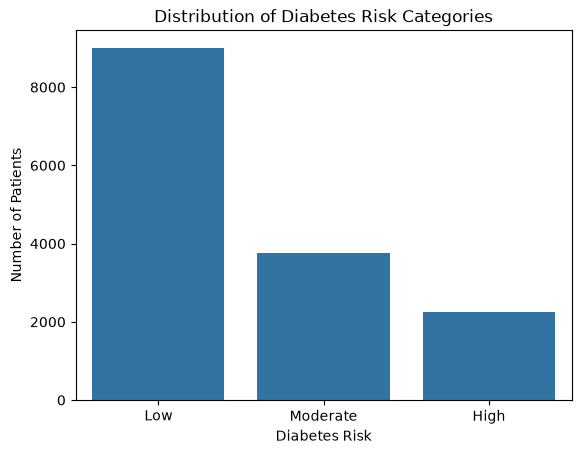

In [4]:
sns.countplot(
    data=info_df,
    x='diabetes_risk',
    order=['Low', 'Moderate', 'High']
)

plt.title('Distribution of Diabetes Risk Categories')
plt.xlabel('Diabetes Risk')
plt.ylabel('Number of Patients')
plt.show()

The distribution of the target variable suggests that the data is imbalanced. There are significantly more low risk patients than moderate and high risk patients. This is important to consider because overall accuracy might be influenced by performance on the largest class.

We can also examine descriptive statistics for the numerical features to better understand their distributions, averages, and ranges.

In [5]:
info_df.describe()

,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


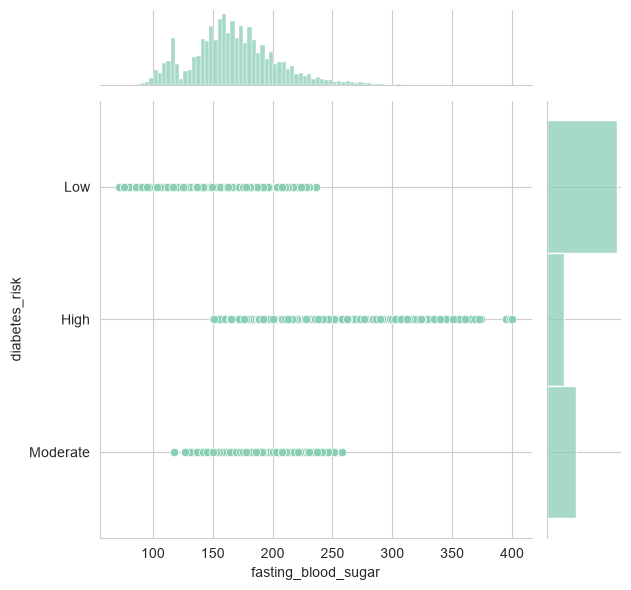

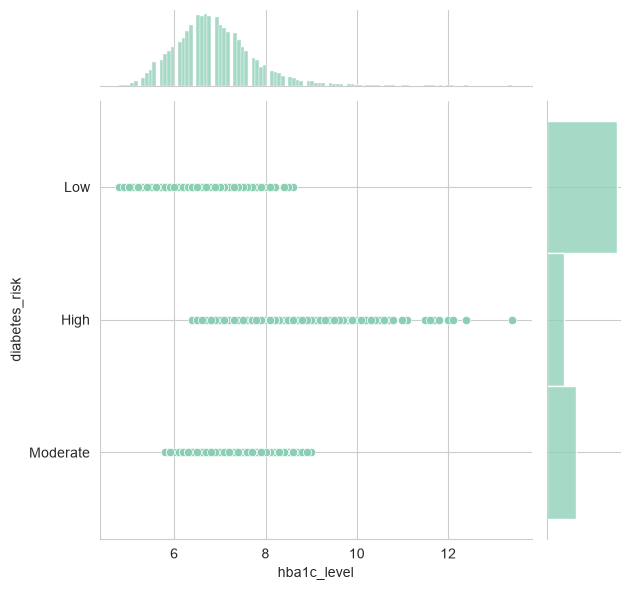

In [6]:
sns.set_palette("BuGn_d")
sns.set_style('whitegrid')
sns.jointplot(x = 'fasting_blood_sugar', y = 'diabetes_risk', data = info_df)
sns.jointplot(x = 'hba1c_level', y = 'diabetes_risk', data = info_df)

As predicted, fasting blood sugar and hba1c level at a glance both appear to have a high correlation with our target variable. To get a better picture of the full dataset however, we can create a heatmap and investigate correlations -

<Axes: >

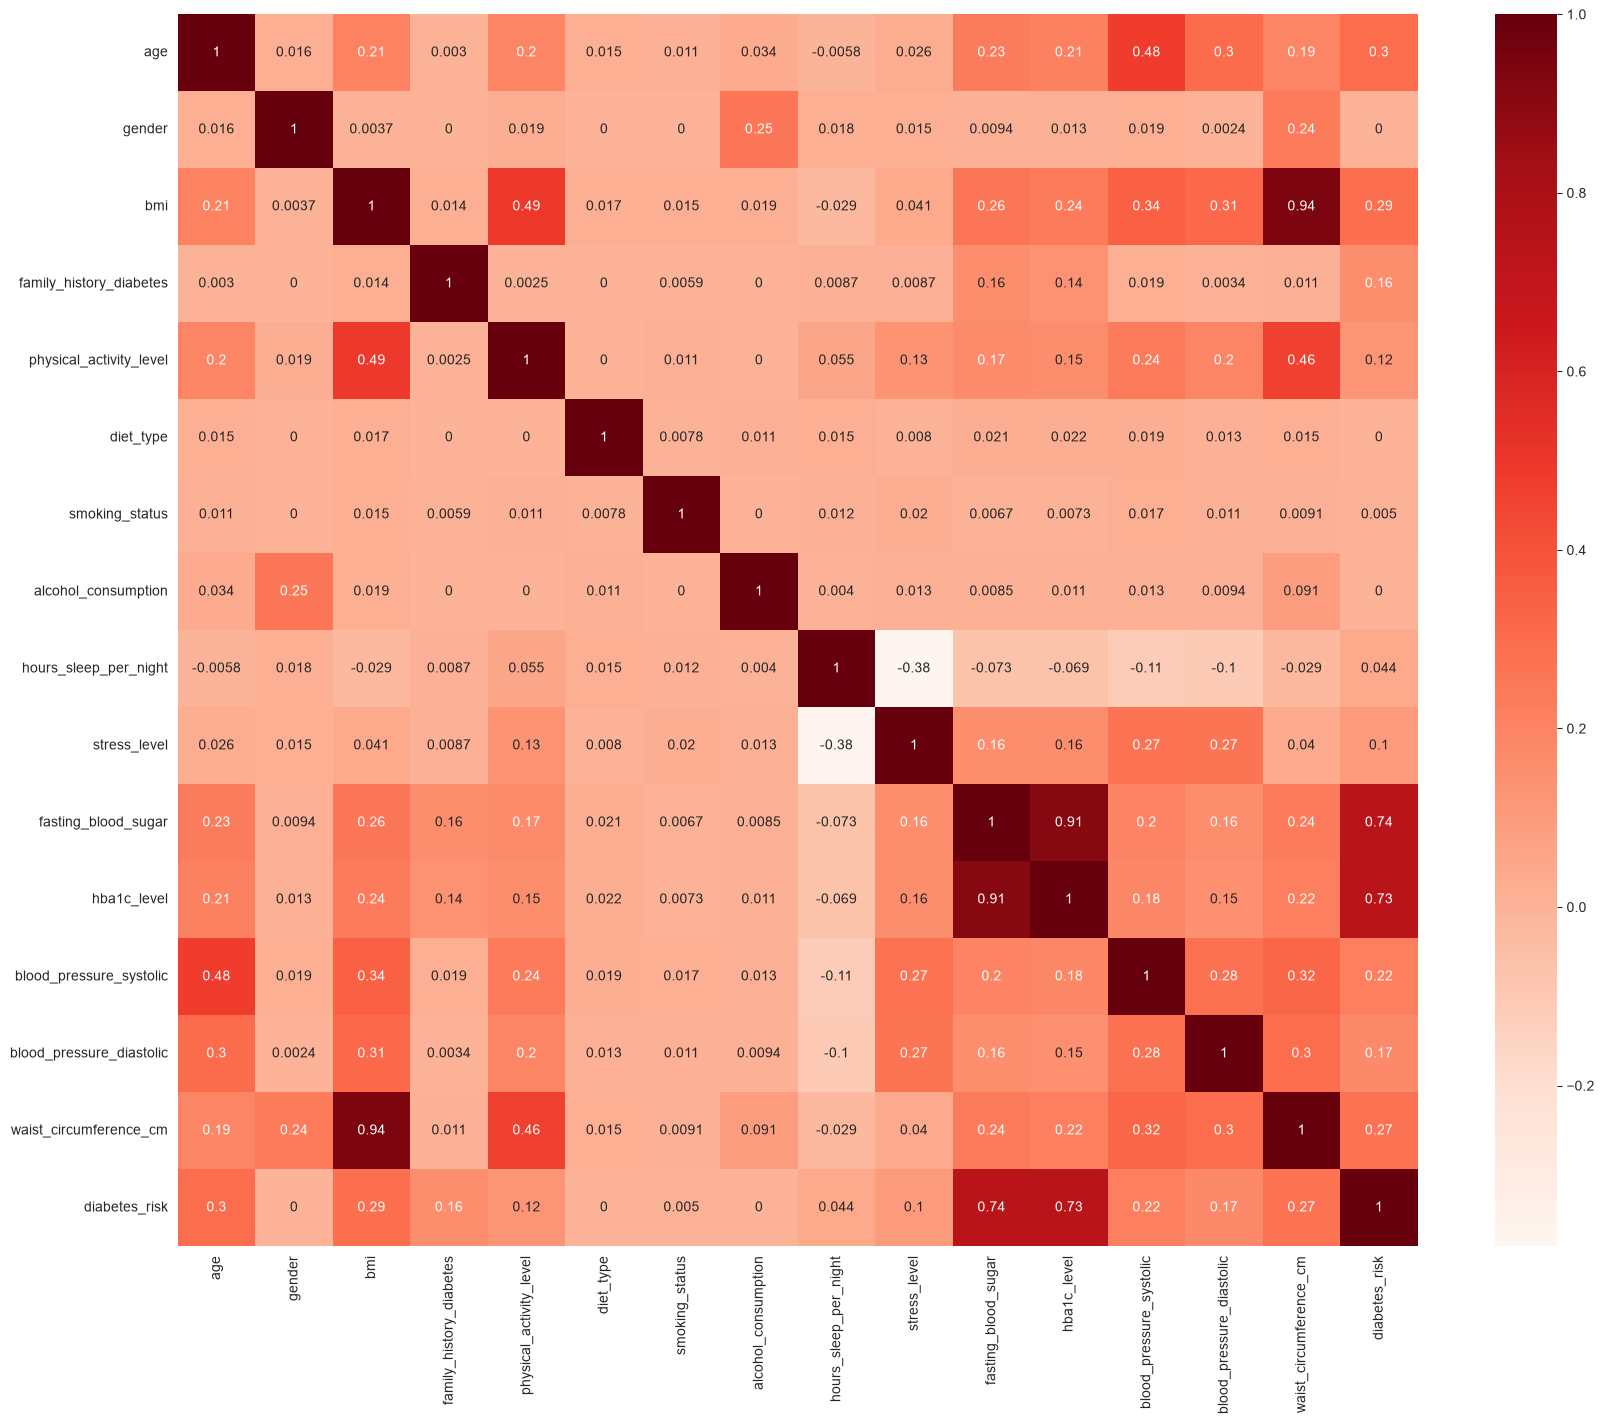

In [7]:
healthhmap = associations(info_df, nominal_columns=['gender','family_history_diabetes','physical_activity_level','diet_type','smoking_status','alcohol_consumption','diabetes_risk'], compute_only=True)
plt.figure(figsize=(20, 16))
sns.heatmap(healthhmap['corr'], cmap="Reds", annot=True)

Looking at the overall heatmap, fasting blood sugar and HbA1c level have the strongest association with diabetes risk out of the variables that we examined, suggesting that they could be particularly useful predictors for our model.

Model 1: Naive Bayes

The goal in this section is to use the Naive Bayes method to classify patients by diabetes risk. To begin we simply split our original data into training and testing sets.

In [8]:
np.random.seed(50)
data_randomized = info_df.sample(frac=1)
# 70% of the data used for training set
trainsize = round(len(data_randomized) * 0.7)

# Build training and testings sets for model, test data = 30%
training_set = data_randomized[:trainsize].reset_index(drop=True)
test_set = data_randomized[trainsize:].reset_index(drop=True)
# Confirm that dimensions match the original data
print(training_set.shape)
print(test_set.shape)

trainX = training_set.iloc[:,:-1]
trainy = training_set['diabetes_risk']
columnnames = trainX.columns
testX = test_set.iloc[:,:-1]
testy = test_set['diabetes_risk']

(10500, 16)
(4500, 16)


The dataset we are using contains both numerical features like BMI and blood sugar as well as categorical features like physical activity level, so we'll need to encode the data as mentioned earlier before we can build our Naive Bayes model.

In [9]:
categorical_columns = ['gender','family_history_diabetes','physical_activity_level','diet_type','smoking_status','alcohol_consumption']
numerical_columns = [item for item in columnnames if item not in categorical_columns]

# checking if columns were properly sorted
print(categorical_columns)
print(numerical_columns)
# creating copies of train and test dataframes to store encoded data
trainX_enc = trainX.copy()
testX_enc = testX.copy()

# using OrdinalEncoder to do categorical features first
ordinalencoder = OrdinalEncoder (
    handle_unknown = "use_encoded_value",
    unknown_value = -1
)

# transforming categorical data within training
trainX_enc[categorical_columns] = ordinalencoder.fit_transform(trainX[categorical_columns])
# doing the same for test data but taking care to avoid using fit() to maintain encoding rules
testX_enc[categorical_columns] = ordinalencoder.transform(testX[categorical_columns])

# in case of an unknown, we add one here to avoid negatives
trainX_enc[categorical_columns] = trainX_enc[categorical_columns] + 1
testX_enc[categorical_columns] = testX_enc[categorical_columns] + 1

['gender', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption']
['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']


Now that we have the categorical data encoded, we move onto the numerical data. Unlike the categorical data, we must partition our numerical columns into distinct, seperate bins as CategoricalNB only accepts discretized numerical values -

In [10]:
# first need to partition numerical columns into distinct bins
for column in numerical_columns:
  bins = pd.qcut(
    trainX_enc[column],
    q=10,
    duplicates="drop",
    retbins=True
  )[1]

  trainX_enc[column] = pd.cut(
    trainX_enc[column],
    bins=bins,
    include_lowest=True
  ).cat.codes

  testX_enc[column] = pd.cut(
    testX_enc[column],
    bins=bins,
    include_lowest=True
  ).cat.codes

# adding one like for the categorical columns to avoid negatives
trainX_enc[numerical_columns] = trainX_enc[numerical_columns] + 1
testX_enc[numerical_columns] = testX_enc[numerical_columns] + 1

# making sure data is stored as int
trainX_enc = trainX_enc.astype(int)
testX_enc = testX_enc.astype(int)

With our training data encoded, we can now fit our model using the encoded training data.

In [11]:
# building Naive-Bayes model object
nbmodel = CategoricalNB()
# fit model
nbmodel.fit(trainX_enc, trainy)
# predictions made using encoded training data
yhattrain = nbmodel.predict(trainX_enc)
# building confusion matrix to check accuracy (with rows representing predicted values)
pd.crosstab(yhattrain, trainy)


diabetes_risk,High,Low,Moderate
row_0,,,
High,1173,20,318
Low,15,5217,587
Moderate,409,1043,1718


From our confusion matrix we can see that our model was fairly accurate in predicting diabetes risk based on the training data (rows represent predicted values and columns actual values). The highest proportion of correctly identified diabetes risk was in the low risk category, while moderate and high risk were a bit less accurate. Another interesting insight to be gained here is that our model tends to incorrectly distinguish moderate risk patients, often classifying them as either low or high risk. We can check the exact accuracy of our model on the training data by producing an accuracy score of correctly predicted outputs.

In [12]:
accuracy_score(yhattrain, trainy)

0.7721904761904762

We need to now test this model on the testing data to determine how well our model generalizes to data it can't see. It is possible that the accuracy score for our test data is higher than our training data, though we can expect a lower accuracy score for the test data on average. Too great a discrepancy either way would mean our model is not reliable across all possible samples.

In [13]:
yhattest = nbmodel.predict(testX_enc)
pd.crosstab(yhattest, testy)

diabetes_risk,High,Low,Moderate
row_0,,,
High,485,10,150
Low,8,2269,270
Moderate,160,441,707


In [14]:
accuracy_score(yhattest, testy)

0.7691111111111111

Our Naive Bayes model achieved an accuracy of 77.22% for the training data and 76.91% on the testing data. Given that these accuracy scores are close to each other, it suggests that it infers fairly well and doesn't significantly overfit. However, the confusion matrix also shows that accuracy is variable between the three diabetes risk categories, so it's safe to say accuracy alone doesn't indicate model performance. To check our accuracy for each category of diabetes risk, we can generate a more detailed classification report -

In [15]:
print(classification_report(testy, yhattest))

              precision    recall  f1-score   support

        High       0.75      0.74      0.75       653
         Low       0.89      0.83      0.86      2720
    Moderate       0.54      0.63      0.58      1127

    accuracy                           0.77      4500
   macro avg       0.73      0.73      0.73      4500
weighted avg       0.78      0.77      0.77      4500



It looks like our model is highly effective at predicting low risk but struggles more with moderate. Recall scores are mostly similar to our precision scores with moderate risk having a significantly higher recall score than the precision score. This suggests that our predictions contain more false positives for moderate diabetes risk than other levels. The potential class imbalance suggests that the F1-score provides a useful measure that balances both precision and recall. We can construct a different model to compare results and attempt to find the best performing model for all risk levels.

Model 2: K-Nearest Neighbors

The goal of our second model is to use K-Nearest Neighbors (KNN) to identify patients by diabetes risk and then compare to our Naive Bayes model. To get started, since KNN uses distances between observations, we should first scale the numerical features and encode the categorical features.

In [16]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

categorical_columns = ['gender','family_history_diabetes','physical_activity_level','diet_type','smoking_status','alcohol_consumption']

numerical_columns = [
    col for col in trainX.columns
    if col not in categorical_columns
]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_columns),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
])

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])

Before we fit the final KNN model, we need to determine an accurate value for K, which represents the number of neighboring observations that we use to make a prediction. Here we can use cross-validation to test values of K only using training data.

In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {'knn__n_neighbors': range(3, 32, 2)}

knn_grid = GridSearchCV(
    knn_model,
    param_grid,
    cv=5,
    scoring='accuracy'
)

knn_grid.fit(trainX, trainy)

print("Best K:", knn_grid.best_params_)
print("Best Cross-Validation Accuracy:", knn_grid.best_score_)

Best K: {'knn__n_neighbors': 31}
Best Cross-Validation Accuracy: 0.7612380952380952


Since K = 31 produced the highest cross-validation accuracy and was also the largest value tested, we expanded the search range to determine whether a larger value of K would perform better.

In [18]:
param_grid = {'knn__n_neighbors': range(3, 62, 2)}

knn_grid = GridSearchCV(
    knn_model,
    param_grid,
    cv=5,
    scoring='accuracy'
)

knn_grid.fit(trainX, trainy)

print("Best K:", knn_grid.best_params_)
print("Best Cross-Validation Accuracy:", knn_grid.best_score_)

Best K: {'knn__n_neighbors': 43}
Best Cross-Validation Accuracy: 0.7635238095238096


After we expanded the search, we found that K = 43 produced the highest 5 fold cross validation accuracy at approximately 76.35%. Since the optimal value was no longer at the edge of our tested range, we then selected K = 43 for the final model. The graph below shows how cross validation accuracy changed across the tested values of K.

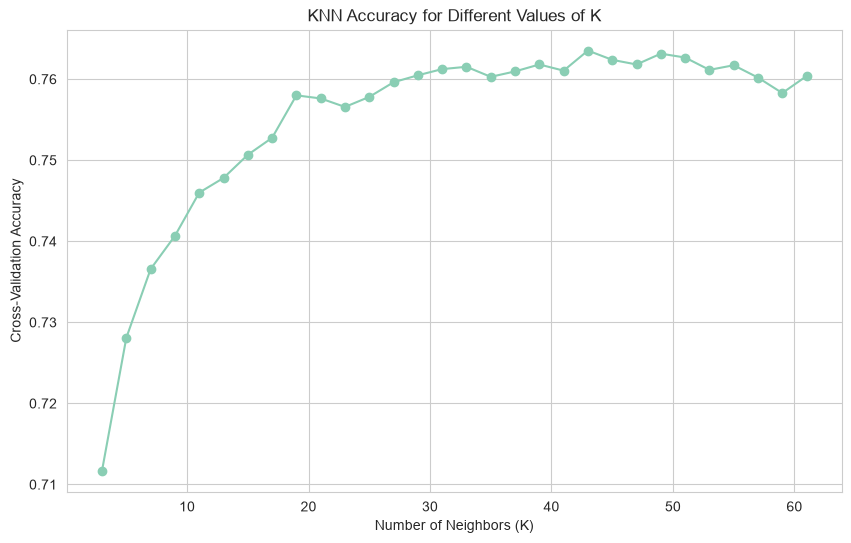

In [19]:
results = pd.DataFrame(knn_grid.cv_results_)

plt.figure(figsize=(10, 6))
plt.plot(
    results['param_knn__n_neighbors'],
    results['mean_test_score'],
    marker='o'
)

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN Accuracy for Different Values of K')
plt.grid(True)
plt.show()

Now that K = 43 was selected through cross-validation, we can use the optimized KNN model to make predictions for both training and testing data, and then compare their performance.

In [20]:
best_knn = knn_grid.best_estimator_

knn_train_pred = best_knn.predict(trainX)
knn_test_pred = best_knn.predict(testX)

print("Training Accuracy:", accuracy_score(trainy, knn_train_pred))
print("Testing Accuracy:", accuracy_score(testy, knn_test_pred))

Training Accuracy: 0.7772380952380953
Testing Accuracy: 0.76


The training and testing accuracies is shown to be relatively close, which suggests that the KNN model does not significantly overfit the training data. We can now look at a confusion matrix to better understand how the performance varies across all three risk categories.

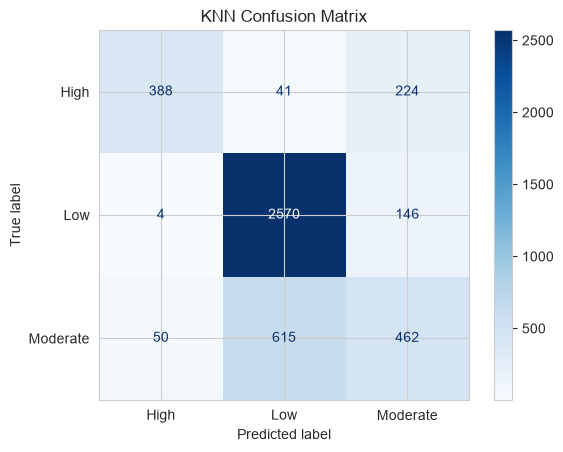

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(testy, knn_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_knn.classes_
)

disp.plot(cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.show()

The KNN model got a testing accuracy of about 76%, with the performance varying significantly across the three risk categories. The model was best at identifying low risk patients, with a 94.5% recall rate. Higher risk patients were identified with a 59.5% recall rate and moderate risk at about 41%. This suggests that the overall accuracy of the model is influenced heavily by the low risk patients, while moderate and high risk patients are more difficult to distinguish.

In [22]:
print(classification_report(testy, knn_test_pred))

              precision    recall  f1-score   support

        High       0.88      0.59      0.71       653
         Low       0.80      0.94      0.86      2720
    Moderate       0.56      0.41      0.47      1127

    accuracy                           0.76      4500
   macro avg       0.74      0.65      0.68      4500
weighted avg       0.75      0.76      0.74      4500



The classification report shows the difference in performance between risk categories. The model got F1 scores of 0.86 for low risk patients, 0.71 for high risk and 0.47 for moderate risk. The somewhat low recall of 0.41 also shows that the model couldn't identify a significant portion of the people in this category.

**Conclusion**

Overall, both of the models produced a similar testing accuracy score, with Naive Bayes achieving 76.91% and KNN achieving 76.0%. However, if we examine the individual risk categories we start to see a larger difference between the two models. Naive Bayes achieved a recall score of 0.74 for high risk, 0.83 for low risk and 0.63 for moderate risk. KNN achieved scores of 0.59, 0.94 and 0.41 respectively. This means that KNN was better for identifying low risk patients, but Naive Bayes was significantly better at identifying the high risk and moderate risk patients.

Since low risk patients made up the majority of the dataset, the overall accuracy alone does not provide the complete picture when it comes to model performance. The Naive Bayes model also got a higher macro-F1 score of 0.73 compared to 0.68 for KNN, which suggests that it performed more consistently across the three classes. Based on this, and the overall results, it seems that Naive Bayes is the better model for this dataset, especially when identifying high risk and moderate risk patients is important.

There is still room for improvement with the models as both were not particularly good at identifying moderate risk patients. Deeper analysis could involve testing additional classification methods or possibly implementing more feature engineering approaches to determine whether the performance for the more difficult risk categories can be improved.